In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path.cwd() / "data" / "processed"

buildings = pd.read_parquet(DATA_DIR / "buildings.parquet")

df = buildings.drop_duplicates(subset="bin").copy()
df = df[df["in_lower_manhattan"] == True].copy()

print("Total buildings:", len(df))

Total buildings: 970


In [2]:
# check the distribution of building class
print("Building class:")
print(df["building_class"].value_counts(dropna=False).head(30))

print("\nBuilding class code:")
print(df["building_class_code"].value_counts(dropna=False).head(30))

print("\nRecord type:")
print(df["record_type"].value_counts(dropna=False))

# check if there are missing data
cols = [
    "building_class",
    "building_class_code",
    "residential_units",
    "total_units",
    "building_area_sqft",
    "n_test_pages"
]

display(df[cols].describe(include="all").T)

Building class:
building_class
condominium (RM)                    162
None                                 82
office (O4)                          80
store building (K4)                  72
office (O5)                          37
office (O6)                          32
elevator apartments (D4)             29
walk-up apartments (C7)              25
elevator apartments (D7)             24
residential with commercial (S3)     24
residential with commercial (S4)     23
store building (K2)                  22
elevator apartments (D5)             21
residential with commercial (S9)     21
condominium (RC)                     19
condominium (R1)                     18
office (O2)                          17
elevator apartments (D6)             15
indoor public assembly (P7)          11
residential with commercial (S5)     11
elevator apartments (D0)             11
elevator apartments (D8)             10
residential with commercial (S2)     10
elevator apartments (D2)             10
walk-up a

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
building_class,888,87,condominium (RM),162,NaN,NaN,NaN,NaN,NaN,NaN,NaN
building_class_code,888,87,RM,162,NaN,NaN,NaN,NaN,NaN,NaN,NaN
residential_units,536.0,<NA>,<NA>,<NA>,67.102612,192.919795,1.0,4.0,6.0,24.0,1712.0
total_units,871.0,<NA>,<NA>,<NA>,51.156142,157.158507,1.0,4.0,6.0,26.0,1722.0
building_area_sqft,883.0,NaN,NaN,NaN,162268.616082,360146.393804,424.0,9108.0,20882.0,125500.0,3553553.0
n_test_pages,970.0,NaN,NaN,NaN,2.586598,14.520731,0.0,0.0,0.0,1.0,278.0


In [3]:
print(
    df["building_class_code"]
    .value_counts(dropna=False)
    .sort_index()
    .to_string()
)

building_class_code
A4        2
A7        5
A9        4
B1        3
B3        1
C0        2
C1        2
C2        5
C3        5
C5        1
C6       10
C7       25
D0       11
D1        1
D2       10
D3        1
D4       29
D5       21
D6       15
D7       24
D8       10
D9        1
DB        1
E9        1
G1        6
H1        5
H2        7
H3        5
H5        2
H8        3
H9        2
HB        4
HR        1
HS        1
I1        1
I5        1
J1        1
K1        2
K2       22
K4       72
K5        1
K6        1
K9        2
M1        9
M2        1
M3        1
M4        1
M9        1
N2        2
N9        1
O2       17
O3       10
O4       80
O5       37
O6       32
O7        3
O8        4
O9        4
P7       11
Q1        1
R1       18
R4        5
RB        7
RC       19
RD        2
RK        1
RM      162
RR        1
RX        1
S1        7
S2       10
S3       24
S4       23
S5       11
S9       21
T9        2
U4        2
U7        2
V1        1
W1        8
W2        1
W3      

In [4]:
# Map building classes into broader categories
def classify_building(code):
    if pd.isna(code):
        return "Unknown"

    code = str(code)

    if code.startswith(("A", "B", "C", "D")) or code in ["R1", "R4", "RC", "RM", "RR", "RX"]:
        return "Residential"

    elif code.startswith("S"):
        return "Mixed-use"

    elif code.startswith("O") or code == "RB":
        return "Office"

    elif code.startswith("K") or code == "RK":
        return "Retail / Commercial"

    elif code.startswith("H"):
        return "Hospitality"

    else:
        return "Other"


df["building_type"] = df["building_class_code"].apply(classify_building)


# Identify buildings with testing records
df["has_testing"] = df["n_test_pages"] > 0


# Calculate testing coverage by building type
summary = (
    df.groupby("building_type")
    .agg(
        n_buildings=("bin", "nunique"),
        n_tested=("has_testing", "sum"),
        median_test_pages=("n_test_pages", "median")
    )
    .reset_index()
)

summary["testing_rate"] = (
    summary["n_tested"] / summary["n_buildings"] * 100
)

summary = summary.sort_values("testing_rate", ascending=False)

summary

,building_type,n_buildings,n_tested,median_test_pages,testing_rate
2,Office,194,76,0.0,39.175258
4,Residential,395,147,0.0,37.215190
3,Other,72,25,0.0,34.722222
5,Retail / Commercial,101,35,0.0,34.653465
0,Hospitality,30,10,0.0,33.333333
1,Mixed-use,96,30,0.0,31.250000
6,Unknown,82,22,0.0,26.829268


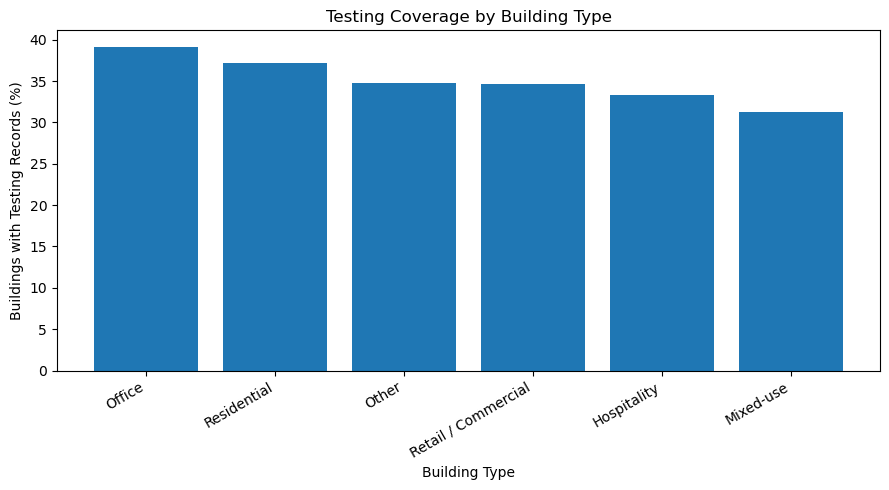

In [5]:
# Visualize the testing coverage by building type
plot_data = summary[summary["building_type"] != "Unknown"]

plt.figure(figsize=(9, 5))
plt.bar(plot_data["building_type"], plot_data["testing_rate"])

plt.ylabel("Buildings with Testing Records (%)")
plt.xlabel("Building Type")
plt.title("Testing Coverage by Building Type")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [6]:
# On the testing coverage level, test if there is significant difference in different types of buildings
from scipy.stats import chi2_contingency

contingency = pd.crosstab(
    df[df["building_type"] != "Unknown"]["building_type"],
    df[df["building_type"] != "Unknown"]["has_testing"]
)

chi2, p, dof, expected = chi2_contingency(contingency)

print(f"Chi-square: {chi2:.3f}")
print(f"p-value: {p:.4f}")

Chi-square: 2.202
p-value: 0.8206


In [7]:
# Aggregate the testing pages of different types of buildings 
intensity = (
    df.groupby("building_type")
    .agg(
        total_test_pages=("n_test_pages", "sum"),
        mean_test_pages=("n_test_pages", "mean"),
        median_test_pages=("n_test_pages", "median")
    )
    .reset_index()
)

summary = summary.merge(intensity, on="building_type")
summary

,building_type,n_buildings,n_tested,median_test_pages_x,testing_rate,total_test_pages,mean_test_pages,median_test_pages_y
0,Office,194,76,0.0,39.175258,566,2.917526,0.0
1,Residential,395,147,0.0,37.215190,1330,3.367089,0.0
2,Other,72,25,0.0,34.722222,97,1.347222,0.0
3,Retail / Commercial,101,35,0.0,34.653465,88,0.871287,0.0
4,Hospitality,30,10,0.0,33.333333,117,3.900000,0.0
5,Mixed-use,96,30,0.0,31.250000,51,0.531250,0.0
6,Unknown,82,22,0.0,26.829268,260,3.170732,0.0


In [8]:
# On the testing pages level, test if there is significant difference in different types of buildings
from scipy.stats import kruskal

# Exclude buildings without testing records and unknown categories
tested = df[
    (df["n_test_pages"] > 0) &
    (df["building_type"] != "Unknown")
].copy()

# Descriptive statistics
intensity_summary = (
    tested.groupby("building_type")["n_test_pages"]
    .agg(["count", "mean", "median", "std"])
    .reset_index()
    .sort_values("mean", ascending=False)
)

display(intensity_summary)

# Kruskal-Wallis test
groups = [
    group["n_test_pages"].values
    for _, group in tested.groupby("building_type")
]

stat, p = kruskal(*groups)

print(f"Kruskal-Wallis H: {stat:.3f}")
print(f"p-value: {p:.4f}")

,building_type,count,mean,median,std
0,Hospitality,10,11.700000,3.0,18.092663
4,Residential,147,9.047619,1.0,31.961092
2,Office,76,7.447368,2.0,18.101488
3,Other,25,3.880000,2.0,4.702127
5,Retail / Commercial,35,2.514286,1.0,2.715656
1,Mixed-use,30,1.700000,1.0,1.022168


Kruskal-Wallis H: 15.630
p-value: 0.0080


In [9]:
#on the testing pages level, test if there is significant difference in different types of buildings when comparing pairs by pairs
!pip install scikit-posthocs

import scikit_posthocs as sp

posthoc = sp.posthoc_dunn(
    tested,
    val_col="n_test_pages",
    group_col="building_type",
    p_adjust="holm"
)

display(posthoc.round(4))

,Hospitality,Mixed-use,Office,Other,Residential,Retail / Commercial
Hospitality,1.0000,0.1121,1.0000,1.0,0.3712,0.1818
Mixed-use,0.1121,1.0000,0.0664,1.0,1.0000,1.0000
Office,1.0000,0.0664,1.0000,1.0,0.2285,0.1494
Other,1.0000,1.0000,1.0000,1.0,1.0000,1.0000
Residential,0.3712,1.0000,0.2285,1.0,1.0000,1.0000
Retail / Commercial,0.1818,1.0000,0.1494,1.0,1.0000,1.0000
